In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False  # 解决保存图像是负号'-'显示为方块的问题

In [12]:
# ① 导入数据集
boston = fetch_openml(name="boston", version=1, as_frame=True, parser="pandas")
df = boston.frame.copy()
# 把目标列 MEDV 重命名为 price
df.rename(columns={"MEDV": "price"}, inplace=True)

In [13]:
# 用均值填充缺失值
df["price"] = df["price"].fillna(df["price"].mean())

In [5]:
# ③ 删除 price == 50.0
df = df[df["price"] != 50.0].reset_index(drop=True)

In [6]:
# ④ 删除 3σ 之外的异常值
mean_p = df["price"].mean()
std_p  = df["price"].std()
df = df[(df["price"] >= mean_p - 3 * std_p) &
        (df["price"] <= mean_p + 3 * std_p)].reset_index(drop=True)
print("清洗后样本数:", len(df))

清洗后样本数: 484


In [7]:
# ⑤ 分别用 RM、LSTAT 建立一元线性回归
results = {}
for feat in ["RM", "LSTAT"]:
    X = df[[feat]].values          # ← 只取这一列，且保持二维
    y = df["price"].values
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42
    )
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[feat] = dict(model=model, X_test=X_test, y_test=y_test, y_pred=y_pred)


RM 线性回归方程: price = 7.1176 * RM + (-22.6843)

LSTAT 线性回归方程: price = -0.7672 * LSTAT + (31.5706)


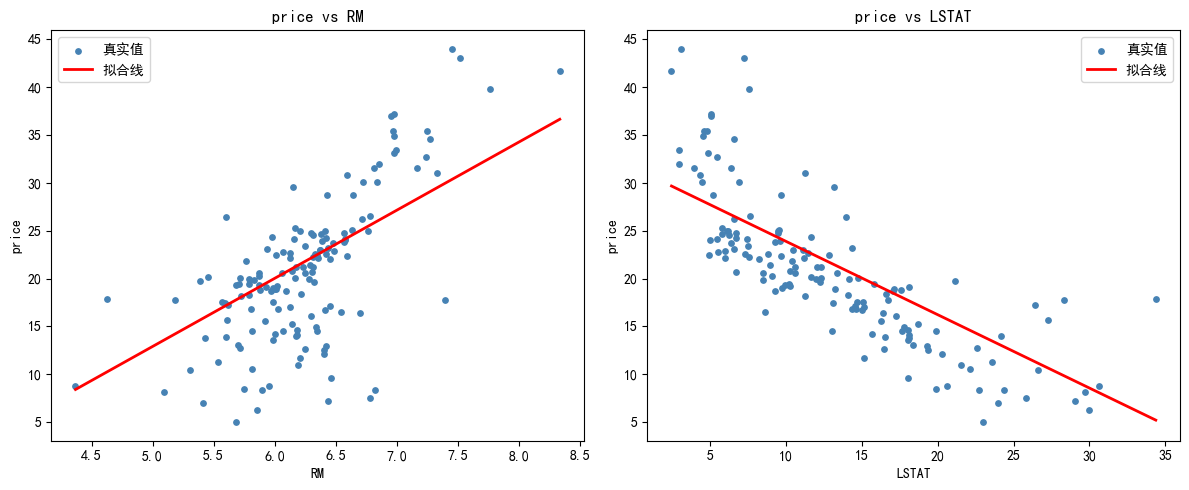

In [10]:
# ⑥ 输出方程 & 画图
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, feat in enumerate(["RM", "LSTAT"]):
    m = results[feat]["model"]
    k, b = m.coef_[0], m.intercept_
    print(f"\n{feat} 线性回归方程: price = {k:.4f} * {feat} + ({b:.4f})")

    ax = axes[i]
    ax.scatter(results[feat]["X_test"], results[feat]["y_test"],
               color="steelblue", s=15, label="真实值")
    x_line = np.linspace(results[feat]["X_test"].min(),
                         results[feat]["X_test"].max(), 200).reshape(-1, 1)
    ax.plot(x_line, m.predict(x_line), color="red", linewidth=2, label="拟合线")
    ax.set_xlabel(feat); ax.set_ylabel("price")
    ax.set_title(f"price vs {feat}")
    ax.legend()
plt.tight_layout()
plt.savefig("lr_fit.png", dpi=150)
plt.show()

In [11]:
# ⑦ 模型评估
print("\n" + "=" * 60)
print(f"{'特征':<8}{'MSE':>12}{'RMSE':>12}{'R²':>12}")
print("-" * 60)
for feat in ["RM", "LSTAT"]:
    y_test = results[feat]["y_test"]
    y_pred = results[feat]["y_pred"]
    mse  = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test, y_pred)
    print(f"{feat:<8}{mse:>12.4f}{rmse:>12.4f}{r2:>12.4f}")


特征               MSE        RMSE          R²
------------------------------------------------------------
RM           34.9078      5.9083      0.4157
LSTAT        23.3121      4.8283      0.6098
